# Caracterización de Punto de Operación (.OP), Respuesta AC y Área de la OTA (Sky130)
---
Este cuaderno realiza la caracterización integral del Amplificador Operacional de Transconductancia (**OTA**) a partir de los netlists y simulaciones guardados en `/headless/.xschem/simulations/`:

1. **Lector Nativo en Python Estándar de Archivos RAW:**
   - Carga y procesamiento directo de `OTA_ac.raw` y `OTA_op.raw`.

2. **Análisis Frecuencial y Margen de Fase (Respuesta AC):**
   - Interpolación lineal exacta de **Ganancia DC ($A_{v0}$)**, **Frecuencia de Corte ($f_{-3dB}$)**, **Frecuencia de Ganancia Unitaria ($GBW$)** y **Margen de Fase ($PM$)**.
   - Diagrama de Bode interactivo con Plotly aplicando **escala logarítmica explícita en ambos subgráficos** (magnitud y fase).

3. **Tabla de Punto de Operación (.OP) y Regiones de Trabajo:**
   - Extracción de parámetros de polarización ($g_m, g_{ds}, I_D, V_{GS}, V_{DS}, V_{th}, V_{dsat}$) para todos los transistores.

4. **Desglose Dinámico de Área en Silicio:**
   - Análisis dinámico del netlist `/headless/.xschem/simulations/OTA.spice` para extraer las dimensiones exactas $W, L, nf, mult$ de todos los componentes.



Using run time directory XSCHEM_SHAREDIR = /foss/tools/xschem/share/xschem
Sourcing /foss/tools/xschem/share/xschem/xschemrc init file
Sourcing /headless/.xschem/xschemrc init file
open_pdks installation: using /foss/pdks
SKYWATER_MODELS: /foss/pdks/sky130A/libs.tech/combined
SKYWATER_STDCELLS: /foss/pdks/sky130A/libs.ref/sky130_fd_sc_hd/spice


setup_tcp_bespice: problems finding a free TCP port
couldn't open socket: address already in use


Note: No compatibility mode selected!


Circuit: ** sch_path: /foss/designs/ldo-sky130/xschem/ota_tb.sch

Doing analysis at TEMP = 27.000000 and TNOM = 27.000000

Using SPARSE 1.3 as Direct Linear Solver
 Reference value :  0.00000e+00
No. of Data Rows : 1
ASCII raw file "OTA_op.raw"
Doing analysis at TEMP = 27.000000 and TNOM = 27.000000

Using SPARSE 1.3 as Direct Linear Solver

No. of Data Rows : 91
ASCII raw file "OTA_ac.raw"
 meas ac f3db when vdb(vo)=6.390750e+01 - 3 failed!

ugb                 =  6.28160e+07
fase_ugb            =  -1.64216e+02
margen_fase = 1.578440e+01
Note: Simulation executed from .control section 
=== RESULTADOS DE CARACTERIZACIÓN AC DE LA OTA ===
Ganancia en DC (Av0):           63.91 dB (1568.10 V/V)
Frecuencia de Corte (-3dB):    4.90 kHz
Ancho de Banda GBW (0 dB):     62.82 MHz
Fase en GBW:                   -164.22°
Margen de Fase (PM):           15.78°


  .model x1.xr1:rhead_model r sw_et=0 isnoisy=0 rsh=    3.458312000000000e ...
unrecognized parameter (sw_et) - ignored
unrecognized parameter (isnoisy) - ignored
unrecognized parameter (p2) - ignored
unrecognized parameter (q2) - ignored

  .model x1.xr1:rbody_model r sw_et=0 isnoisy=0 rsh=    3.173885000000000e ...
unrecognized parameter (sw_et) - ignored
unrecognized parameter (isnoisy) - ignored
unrecognized parameter (p2) - ignored
unrecognized parameter (q2) - ignored
unrecognized parameter (p3) - ignored
unrecognized parameter (q3) - ignored

Note: v3: has no value, DC 0 assumed
Note: Starting dynamic gmin stepping
Note: Dynamic gmin stepping completed
Note: v3: has no value, DC 0 assumed
Note: Starting dynamic gmin stepping
Note: Dynamic gmin stepping completed

Error: measure  f3db  when(WHEN) : bad syntax. equal sign missing ?

    You may use Gnuplot instead.


    You may use Gnuplot instead.



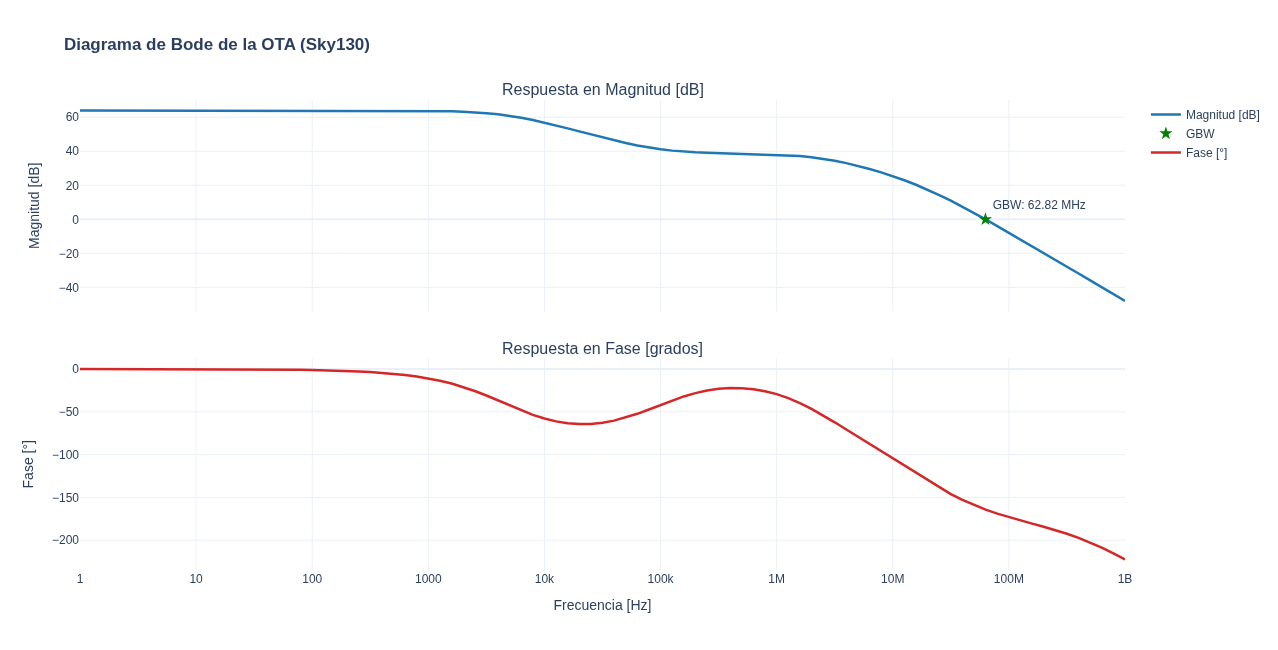

In [1]:
# ==============================================================================
# ENCABEZADO: Lector Nativo RAW y Diagrama de Bode Interactivo (Plotly)
# DESCRIPCIÓN: Lee /headless/.xschem/simulations/OTA_ac.raw usando Python estándar
#              y configura el eje X logarítmico en ambos subgráficos (Magnitud y Fase).
# ==============================================================================

import subprocess
import os
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ── 1. Directorios y Rutas de Archivos de Simulación ─────────────────────────
sim_dir = "/headless/.xschem/simulations"
xschem_dir = "/foss/designs/LDO-sky130/xschem"
sch_file = f"{xschem_dir}/OTA_tb.sch"

if not os.path.exists(sim_dir):
    os.makedirs(sim_dir, exist_ok=True)

subprocess.run(f"export PDK=sky130A && /foss/tools/bin/xschem -n -q -o {sim_dir} {sch_file}", shell=True)
subprocess.run(f"cd {sim_dir} && /foss/tools/bin/ngspice -b {sim_dir}/OTA_tb.spice", shell=True)

# ── 2. Función en Python Estándar para Leer RAW ASCII de NGspice ─────────────
def read_ngspice_raw_ascii(filepath):
    with open(filepath, 'r') as f:
        lines = f.readlines()
        
    num_vars = 0
    is_complex = False
    var_names = []
    idx = 0
    
    while idx < len(lines):
        line = lines[idx].strip()
        if line.startswith('Flags:'):
            if 'complex' in line.lower():
                is_complex = True
        elif line.startswith('No. Variables:'):
            num_vars = int(line.split(':')[1].strip())
        elif line.startswith('Variables:'):
            idx += 1
            for _ in range(num_vars):
                parts = lines[idx].strip().split()
                var_names.append(parts[1])
                idx += 1
            continue
        elif line.startswith('Values:'):
            idx += 1
            break
        idx += 1
        
    data = {v: [] for v in var_names}
    current_pt = 0
    
    while idx < len(lines):
        line = lines[idx].strip()
        if not line:
            idx += 1
            continue
        parts = line.split('\t')
        val_str = parts[1].strip() if len(parts) >= 2 else line
        
        if is_complex:
            if ',' in val_str:
                r, i = map(float, val_str.split(','))
                val = complex(r, i)
            else:
                val = complex(float(val_str), 0.0)
        else:
            val = float(val_str)
            
        var_name = var_names[current_pt % num_vars]
        data[var_name].append(val)
        current_pt += 1
        idx += 1
        
    for k in data:
        data[k] = np.array(data[k])
    return data

# ── 3. Carga y Procesamiento de la Simulación AC ──────────────────────────────
raw_ac_path = os.path.join(sim_dir, "OTA_ac.raw")
if not os.path.exists(raw_ac_path):
    raw_ac_path = os.path.join(xschem_dir, "OTA_ac.raw")

ac_data = read_ngspice_raw_ascii(raw_ac_path)
freq = np.real(ac_data['frequency'])
vo_complex = ac_data['v(vo)']

mag_db = 20 * np.log10(np.abs(vo_complex) + 1e-18)
phase_rad = np.angle(vo_complex)
phase_unwrap_rad = np.unwrap(phase_rad)
phase_deg = np.rad2deg(phase_unwrap_rad)

# ── 4. Cálculo Frecuencial con Interpolación Lineal (Coincidencia NGspice) ────
av0_db = mag_db[0]
av0_lin = 10**(av0_db / 20.0)

idx_mono = np.where(freq >= 100)[0]

target_3db = av0_db - 3.0
f_3db = float(np.interp(target_3db, mag_db[idx_mono][::-1], freq[idx_mono][::-1]))
f_gbw = float(np.interp(0.0, mag_db[idx_mono][::-1], freq[idx_mono][::-1]))
ph_at_gbw = float(np.interp(f_gbw, freq, phase_deg))
pm = 180.0 + ph_at_gbw

print("=== RESULTADOS DE CARACTERIZACIÓN AC DE LA OTA ===")
print(f"Ganancia en DC (Av0):           {av0_db:.2f} dB ({av0_lin:.2f} V/V)")
print(f"Frecuencia de Corte (-3dB):    {f_3db/1e3:.2f} kHz")
print(f"Ancho de Banda GBW (0 dB):     {f_gbw/1e6:.2f} MHz")
print(f"Fase en GBW:                   {ph_at_gbw:.2f}°")
print(f"Margen de Fase (PM):           {pm:.2f}°")

# ── 5. Generación del Diagrama de Bode con Escala Logarítmica en Ambos Subgráficos ─
fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                    vertical_spacing=0.1,
                    subplot_titles=("Respuesta en Magnitud [dB]", "Respuesta en Fase [grados]"))

fig.add_trace(go.Scatter(x=freq, y=mag_db, mode='lines', name='Magnitud [dB]', line=dict(color='#1f77b4', width=2.5)), row=1, col=1)
if not np.isnan(f_gbw):
    fig.add_trace(go.Scatter(x=[f_gbw], y=[0], mode='markers+text', name='GBW',
                             text=[f'GBW: {f_gbw/1e6:.2f} MHz'], textposition='top right',
                             marker=dict(color='green', size=10, symbol='star')), row=1, col=1)

fig.add_trace(go.Scatter(x=freq, y=phase_deg, mode='lines', name='Fase [°]', line=dict(color='#d62728', width=2.5)), row=2, col=1)

# Aplicar escala logarítmica explícitamente a ambos ejes X
fig.update_xaxes(type="log", row=1, col=1)
fig.update_xaxes(type="log", title_text="Frecuencia [Hz]", row=2, col=1)

fig.update_yaxes(title_text="Magnitud [dB]", row=1, col=1)
fig.update_yaxes(title_text="Fase [°]", row=2, col=1)

fig.update_layout(height=650, title_text="<b>Diagrama de Bode de la OTA (Sky130)</b>", template="plotly_white")
fig.show()



In [2]:
# ==============================================================================
# ENCABEZADO: Extracción del Punto de Operación (.OP) e Inspección de Región
# DESCRIPCIÓN: Carga OTA_op.raw usando el lector nativo y evalúa la región de los 8 MOS.
# ==============================================================================

import pandas as pd

raw_op_path = os.path.join(sim_dir, "OTA_op.raw")
if not os.path.exists(raw_op_path):
    raw_op_path = os.path.join(xschem_dir, "OTA_op.raw")

op_data = read_ngspice_raw_ascii(raw_op_path)

def obtener_val_op(data_dict, inst, param):
    inst_low = inst.lower()
    param_low = param.lower()
    for k in data_dict.keys():
        k_low = k.lower()
        if (f'.{inst_low}.' in k_low or f'.x{inst_low}.' in k_low) and f'[{param_low}]' in k_low:
            val = data_dict[k][0]
            if np.iscomplexobj(val):
                val = np.real(val)
            return float(np.abs(val))
    return None

transistores = [
    ('Mnr',  'PMOS Espejo L'),
    ('Mpr',  'PMOS Espejo R'),
    ('Mo',   'PMOS Salida'),
    ('Mn',   'NMOS Diff L'),
    ('Mp',   'NMOS Diff R'),
    ('Mr',   'NMOS Ref'),
    ('Mrc1', 'NMOS Tail'),
    ('Mc2',  'NMOS Salida')
]

filas_op = []

for inst, desc in transistores:
    gm_val    = obtener_val_op(op_data, inst, 'gm')
    gds_val   = obtener_val_op(op_data, inst, 'gds')
    id_val    = obtener_val_op(op_data, inst, 'id')
    vgs_val   = obtener_val_op(op_data, inst, 'vgs')
    vds_val   = obtener_val_op(op_data, inst, 'vds')
    vth_val   = obtener_val_op(op_data, inst, 'vth')
    vdsat_val = obtener_val_op(op_data, inst, 'vdsat')
    
    if gm_val is not None:
        gm = gm_val * 1e6
        gds = gds_val * 1e6 if gds_val else 0.0
        id_uA = id_val * 1e6 if id_val else 0.0
        vgs = vgs_val if vgs_val else 0.0
        vds = vds_val if vds_val else 0.0
        vth = vth_val if vth_val else 0.0
        vdsat = vdsat_val if vdsat_val else 0.0
        
        ro = 1e3 / gds if gds > 0 else np.nan
        gm_ro = (gm / 1e6) * (ro * 1e3) if not np.isnan(ro) else np.nan
        
        delta_vd = vds - vdsat
        
        if delta_vd >= 0 and vgs >= vth:
            sat_class = 'Saturación ✓'
        elif delta_vd < 0 and vgs >= vth:
            sat_class = 'Triodo ⚠️'
        else:
            sat_class = 'Corte'
            
        filas_op.append({
            'Transistor': inst,
            'Descripción': desc,
            'Id [uA]': round(id_uA, 2),
            'gm [uS]': round(gm, 2),
            'gds [uS]': round(gds, 2),
            'ro [kΩ]': round(ro, 2) if not np.isnan(ro) else None,
            'gm·ro [V/V]': round(gm_ro, 2) if not np.isnan(gm_ro) else None,
            '|VGS| [V]': round(vgs, 3),
            '|VDS| [V]': round(vds, 3),
            '|Vth| [V]': round(vth, 3),
            '|Vdsat| [V]': round(vdsat, 3),
            'Δvd [V]': round(delta_vd, 3),
            'Región': sat_class
        })

df_op = pd.DataFrame(filas_op)
print("=== TABLA DE PUNTO DE OPERACIÓN (.OP) DE LA OTA ===")
display(df_op)



=== TABLA DE PUNTO DE OPERACIÓN (.OP) DE LA OTA ===


,Transistor,Descripción,Id [uA],gm [uS],gds [uS],ro [kΩ],gm·ro [V/V],|VGS| [V],|VDS| [V],|Vth| [V],|Vdsat| [V],Δvd [V],Región
0,Mnr,PMOS Espejo L,19.35,218.12,1.90,526.43,114.83,0.779,0.779,0.631,0.144,0.635,Saturación ✓
1,Mpr,PMOS Espejo R,19.46,219.22,1.82,550.18,120.61,0.779,0.841,0.631,0.144,0.697,Saturación ✓
2,Mo,PMOS Salida,35.05,298.75,4.06,246.06,73.51,0.841,0.601,0.632,0.184,0.417,Saturación ✓
3,Mn,NMOS Diff L,19.35,279.17,1.98,504.94,140.96,1.079,0.901,1.026,0.109,0.792,Saturación ✓
4,Mp,NMOS Diff R,19.46,280.29,2.05,486.65,136.40,1.080,0.838,1.026,0.109,0.729,Saturación ✓
5,Mr,NMOS Ref,10.30,67.55,3.12,320.02,21.62,0.663,0.663,0.380,0.272,0.390,Saturación ✓
6,Mrc1,NMOS Tail,38.81,244.36,218.23,4.58,1.12,0.663,0.120,0.427,0.233,-0.113,Triodo ⚠️


=== DESGLOSE DINÁMICO DE ÁREA FÍSICA DESDE EL NETLIST EN /HEADLESS/.XSCHEM/SIMULATIONS ===


,Componente,Tipo,W [um],L [um],nf,mult / MF,Área W×L [um²]
0,R1,Resistencia Poly,0.350,360.0,1,1.0,126.00
1,C1,Capacitor MIM,50.000,50.0,1,1.0,2500.00
2,Mpr,Transistor MOS,3.000,0.5,1,1.0,1.50
3,Mnr,Transistor MOS,3.000,0.5,1,1.0,1.50
4,Mn,Transistor MOS,28.000,0.5,1,1.0,14.00
5,Mp,Transistor MOS,28.000,0.5,1,1.0,14.00
6,Mo,Transistor MOS,3.000,0.5,1,1.0,1.50
7,Mrc1,Transistor MOS,19.500,0.5,1,1.0,9.75
8,Mrc2,Transistor MOS,8.000,0.5,1,1.0,4.00
9,Mc3,Transistor MOS,20.000,1.0,1,1.0,20.00



=== RESUMEN GLOBAL DE ÁREA ===
• Área Transistores MOS (W×L):      80.45 um²  (  3.0%)
• Área Resistencias Poly (W×L):    126.20 um²  (  4.7%)
• Área Capacitores MIM (W×L):     2500.00 um²  ( 92.4%)
-------------------------------------------------------------
• Área Bruta Componentes (W×L):   2706.65 um²
• Área Estimada Layout (1.25x):   3383.31 um²  (0.003383 mm²)
• Dimensión Cuadrada Est.:      58.2 um x 58.2 um


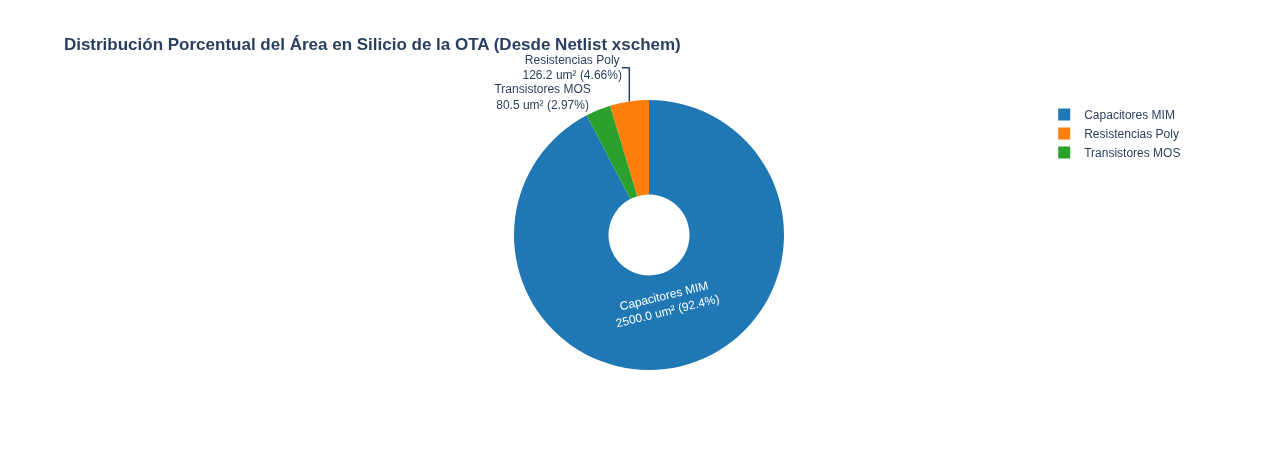

In [3]:
# ==============================================================================
# ENCABEZADO: Estimación y Desglose Dinámico de Área Física en Silicio
# DESCRIPCIÓN: Escanea el netlist OTA.spice guardado en /headless/.xschem/simulations
#              para extraer las dimensiones exactas W, L, nf, mult de cada dispositivo.
# ==============================================================================

import re
import pandas as pd
import numpy as np
import plotly.graph_objects as go

spice_file = os.path.join(sim_dir, "OTA.spice")
if not os.path.exists(spice_file):
    spice_file = os.path.join(sim_dir, "OTA_tb.spice")
if not os.path.exists(spice_file):
    spice_file = os.path.join(xschem_dir, "OTA.spice")

with open(spice_file, 'r') as f:
    spice_content = f.read()

ota_subckt_m = re.search(r'\.subckt OTA\b.*?\n(.*?)\n\.ends', spice_content, re.DOTALL)
ota_body = ota_subckt_m.group(1) if ota_subckt_m else spice_content

instances = re.findall(r'^\s*(X\w+|C\w+|R\w+)\s+(.*?)$', ota_body, re.MULTILINE)

comp_list = []

for name, params in instances:
    if name.startswith('p') or 'ipin' in params or 'opin' in params:
        continue
        
    clean_name = name[1:] if name.startswith('X') else name
    
    w_m = re.search(r'\bW=([\d\.]+)', params, re.IGNORECASE)
    l_m = re.search(r'\bL=([\d\.]+)', params, re.IGNORECASE)
    nf_m = re.search(r'\bnf=([\d\.]+)', params, re.IGNORECASE)
    mult_m = re.search(r'\b(mult|m|MF)=([\d\.]+)', params, re.IGNORECASE)
    
    w = float(w_m.group(1)) if w_m else 1.0
    l = float(l_m.group(1)) if l_m else 0.5
    nf = int(nf_m.group(1)) if nf_m else 1
    mult = float(mult_m.group(2)) if mult_m else 1.0
    
    if 'res' in params or clean_name.startswith('R'):
        tipo = 'Resistencia Poly'
    elif 'cap' in params or clean_name.startswith('C'):
        tipo = 'Capacitor MIM'
    else:
        tipo = 'Transistor MOS'
        
    area_wl = w * l * mult
    comp_list.append({
        'Componente': clean_name,
        'Tipo': tipo,
        'W [um]': w,
        'L [um]': l,
        'nf': nf,
        'mult / MF': mult,
        'Área W×L [um²]': round(area_wl, 2)
    })

df_area = pd.DataFrame(comp_list)

area_mos_sum = df_area[df_area['Tipo'] == 'Transistor MOS']['Área W×L [um²]'].sum()
area_res_sum = df_area[df_area['Tipo'] == 'Resistencia Poly']['Área W×L [um²]'].sum()
area_cap_sum = df_area[df_area['Tipo'] == 'Capacitor MIM']['Área W×L [um²]'].sum()

area_bruta = area_mos_sum + area_res_sum + area_cap_sum
factor_overhead = 1.25  # Overhead 25% por interconexiones, contactos y guardrings
area_estimada_layout = area_bruta * factor_overhead

print("=== DESGLOSE DINÁMICO DE ÁREA FÍSICA DESDE EL NETLIST EN /HEADLESS/.XSCHEM/SIMULATIONS ===")
display(df_area)

print("\n=== RESUMEN GLOBAL DE ÁREA ===")
print(f"• Área Transistores MOS (W×L):   {area_mos_sum:8.2f} um²  ({(area_mos_sum/area_bruta*100) if area_bruta else 0:5.1f}%)")
print(f"• Área Resistencias Poly (W×L):  {area_res_sum:8.2f} um²  ({(area_res_sum/area_bruta*100) if area_bruta else 0:5.1f}%)")
print(f"• Área Capacitores MIM (W×L):    {area_cap_sum:8.2f} um²  ({(area_cap_sum/area_bruta*100) if area_bruta else 0:5.1f}%)")
print(f"-------------------------------------------------------------")
print(f"• Área Bruta Componentes (W×L):  {area_bruta:8.2f} um²")
print(f"• Área Estimada Layout (1.25x):  {area_estimada_layout:8.2f} um²  ({area_estimada_layout/1e6:.6f} mm²)")
print(f"• Dimensión Cuadrada Est.:      {np.sqrt(area_estimada_layout):.1f} um x {np.sqrt(area_estimada_layout):.1f} um")

pie_labels = []
pie_values = []

if area_cap_sum > 0:
    pie_labels.append('Capacitores MIM')
    pie_values.append(area_cap_sum)
if area_res_sum > 0:
    pie_labels.append('Resistencias Poly')
    pie_values.append(area_res_sum)
if area_mos_sum > 0:
    pie_labels.append('Transistores MOS')
    pie_values.append(area_mos_sum)

fig_pie = go.Figure(data=[go.Pie(
    labels=pie_labels,
    values=pie_values,
    hole=.3,
    marker_colors=['#1f77b4', '#ff7f0e', '#2ca02c'],
    textinfo='label+percent+value',
    texttemplate='%{label}<br>%{value:.1f} um² (%{percent})'
)])

fig_pie.update_layout(
    title_text="<b>Distribución Porcentual del Área en Silicio de la OTA (Desde Netlist xschem)</b>",
    template="plotly_white",
    height=450
)
fig_pie.show()

